# Evaluation functions

In [15]:
import json
import os
import matplotlib.pyplot as plt

In [18]:
def calc_SRR_from_json(file_path, get_rank_list=False):
    with open(file_path, "r") as f:
        data = json.load(f)
    
    truths = data["groundtruth"]
    preds = data["prediction"]

    total_score = 0
    count = 0
    rank_list = []
    for x, y_list in preds.items():
        count += 1
        y_true = truths[x] 

        pred_rank = None
        if y_true in y_list:
            pred_rank = y_list.index(y_true) + 1
            total_score += 1/pred_rank
        rank_list.append(pred_rank)
    
    if get_rank_list:
        return total_score, count, rank_list
    else:
        return total_score, count

def calc_MRR(base_dir: str):
    SRR = 0
    count = 0
    rank_list = []
    for json_file in os.listdir(base_dir):
        json_path = os.path.join(base_dir, json_file)
        _srr, _count = calc_SRR_from_json(json_path)
        SRR += _srr
        count += _count

    return SRR/count, count

def get_pred_ranks(base_dir: str):
    rank_list = []
    for json_file in os.listdir(base_dir):
        json_path = os.path.join(base_dir, json_file)
        _, __, ranks= calc_SRR_from_json(json_path, get_rank_list=True)
        rank_list.extend(ranks)

    return rank_list

def get_ranks_statistics(base_dir: str):
    rank_list = get_pred_ranks(base_dir)
    statistics = [0, 0, 0, 0, 0, 0]
    for r in rank_list:
        if r is None: statistics[5] += 1
        else: statistics[r - 1] += 1
    return statistics


def draw_histogram(statistics: list):
    labels = ['1', '2', '3', '4', '5', 'Not found']
    positions = range(len(statistics))

    plt.figure()
    plt.bar(positions, statistics)
    plt.xticks(positions, labels)
    plt.xlabel("Predicted rank")
    plt.ylabel("Count")
    plt.title("Histogram of predicted rank quantities")
    plt.show()


# Evaluating

In [4]:
MRR, count_test = calc_MRR("eval")
print("Number of test-cases:", count_test)
print("MRR:", MRR)

Number of test-cases: 174
MRR: 0.9741379310344828


In [13]:
statistics = get_ranks_statistics("eval")
for i in range(5):
    print(f"Number of correct arxiv predicted at rank {i + 1}: {statistics[i]}")
print("Number of references are not in top 5 predicted:", statistics[-1])

Number of correct arxiv predicted at rank 1: 169
Number of correct arxiv predicted at rank 2: 1
Number of correct arxiv predicted at rank 3: 0
Number of correct arxiv predicted at rank 4: 0
Number of correct arxiv predicted at rank 5: 0
Number of references are not in top 5 predicted: 4


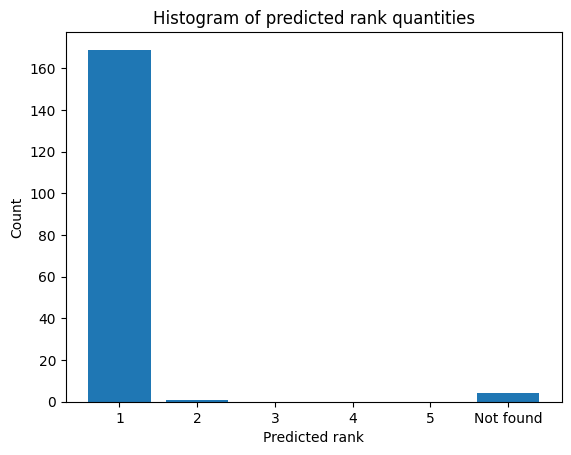

In [19]:
draw_histogram(statistics)